# 02 — Image Segmentation & HOG

**Phụ trách:** Tiến · **Chủ đề:** Chapter 4 — *Exploring Image Data*  
**Mục tiêu:** quan sát phân ngưỡng trên một ảnh CIFAR-10 và trích xuất đặc trưng Histogram of Oriented Gradients (HOG).

Notebook dùng mẫu đầu tiên `x_train[0]` như ví dụ trong sách. Ngưỡng `100` và cách chuyển xám bằng trung bình ba kênh được đối chiếu với ví dụ sách. So sánh thêm ngưỡng `60/100/140` là phần mở rộng theo phân công nhóm.

> Thực nghiệm này minh họa phép biến đổi ảnh, không huấn luyện mô hình. Khi không có mặt nạ nhãn đúng (ground truth), tỷ lệ pixel vượt ngưỡng không phải độ chính xác segmentation.


## 01. Chuẩn bị môi trường và lấy ảnh CIFAR-10

`keras.datasets.cifar10.load_data()` tải hoặc dùng cache CIFAR-10. Dataset không được lưu trong repo. Chọn `x_train[0]` để giữ cùng mẫu cho segmentation và HOG; nhãn được in ra để nhận diện mẫu.


Ảnh mẫu: x_train[0] — lớp 6 (frog)
Shape: (32, 32, 3); dtype: uint8
Miền giá trị RGB: 0–255
Kết quả sẽ lưu tại: C:\N4_HKI\PR_Seminar_BaKhi\outputs\tien


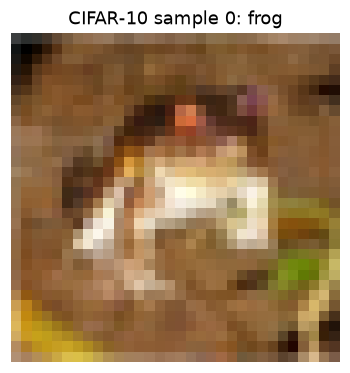

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from keras.datasets import cifar10
from skimage.feature import hog

project_root = next(
    (
        folder
        for folder in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
        if (folder / "notebooks").is_dir() and (folder / "outputs").is_dir()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Không tìm thấy gốc repo. Hãy mở toàn bộ PR_Seminar_BaKhi trong VS Code."
    )

OUTPUT_DIR = project_root / "outputs" / "tien"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

(x_train, y_train), _ = cifar10.load_data()
sample_image = x_train[0]
sample_label = int(y_train[0, 0])
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
]

assert sample_image.shape == (32, 32, 3)
assert sample_image.dtype == np.uint8
assert 0 <= sample_label < len(class_names)

print(f"Ảnh mẫu: x_train[0] — lớp {sample_label} ({class_names[sample_label]})")
print(f"Shape: {sample_image.shape}; dtype: {sample_image.dtype}")
print(f"Miền giá trị RGB: {sample_image.min()}–{sample_image.max()}")
print(f"Kết quả sẽ lưu tại: {OUTPUT_DIR}")

plt.figure(figsize=(3.5, 3.5))
plt.imshow(sample_image)
plt.title(f"CIFAR-10 sample 0: {class_names[sample_label]}")
plt.axis("off")
plt.tight_layout()
plt.show()


## 02. Segmentation bằng ngưỡng 100

Tạo ảnh xám bằng trung bình ba kênh RGB, sau đó đặt pixel thành 255 nếu cường độ **lớn hơn** ngưỡng, còn lại đặt thành 0. Đây là phép phân ngưỡng nhị phân đơn giản; kết quả phụ thuộc nội dung và độ sáng của mẫu.


Ngưỡng: 100 (pixel được chọn khi gray > 100)
Pixel được chọn: 42.58%


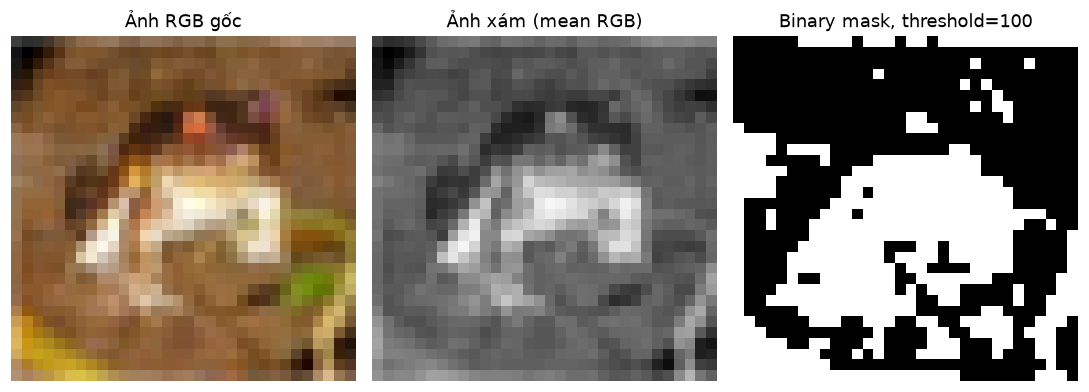

In [2]:
gray_image = np.mean(sample_image, axis=2)
threshold = 100
segmented_image = np.where(gray_image > threshold, 255, 0).astype(np.uint8)

assert gray_image.shape == sample_image.shape[:2]
assert set(np.unique(segmented_image)).issubset({0, 255})

selected_percent_100 = np.mean(gray_image > threshold) * 100
print(f"Ngưỡng: {threshold} (pixel được chọn khi gray > {threshold})")
print(f"Pixel được chọn: {selected_percent_100:.2f}%")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].imshow(sample_image)
axes[0].set_title("Ảnh RGB gốc")
axes[1].imshow(gray_image, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Ảnh xám (mean RGB)")
axes[2].imshow(segmented_image, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Binary mask, threshold=100")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_threshold_100.png", dpi=180, bbox_inches="tight")
plt.show()


## 03. Mở rộng: so sánh ngưỡng 60 / 100 / 140

Giữ nguyên một ảnh xám và thay đổi duy nhất giá trị ngưỡng. Vì mask chọn pixel theo điều kiện `gray > threshold`, tăng ngưỡng không thể làm tăng tỷ lệ pixel được chọn. Tỷ lệ này chỉ mô tả đầu ra của phép biến đổi; không đánh giá độ chính xác phân đoạn đối tượng.


Tỷ lệ pixel được chọn (gray > threshold):
  threshold= 60:  91.41%
  threshold=100:  42.58%
  threshold=140:  15.23%
Lưu ý: đây không phải accuracy/IoU; không có ground-truth mask để đánh giá.


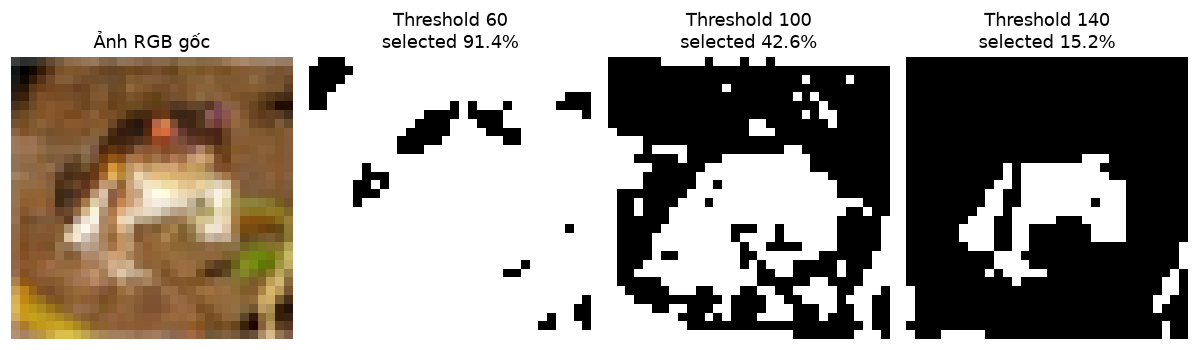

In [3]:
thresholds = (60, 100, 140)
fig, axes = plt.subplots(1, len(thresholds) + 1, figsize=(11, 3.3))
axes[0].imshow(sample_image)
axes[0].set_title("Ảnh RGB gốc")
axes[0].axis("off")

selected_percentages = []
for ax, value in zip(axes[1:], thresholds):
    mask = gray_image > value
    selected_percent = np.mean(mask) * 100
    selected_percentages.append(selected_percent)
    ax.imshow(mask, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Threshold {value}\nselected {selected_percent:.1f}%")
    ax.axis("off")

assert all(
    earlier >= later
    for earlier, later in zip(selected_percentages, selected_percentages[1:])
)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_threshold_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

print("Tỷ lệ pixel được chọn (gray > threshold):")
for value, percent in zip(thresholds, selected_percentages):
    print(f"  threshold={value:3d}: {percent:6.2f}%")
print("Lưu ý: đây không phải accuracy/IoU; không có ground-truth mask để đánh giá.")


## 04. Trích xuất đặc trưng HOG

HOG (Histogram of Oriented Gradients) mô tả cấu trúc cục bộ thông qua hướng và độ lớn gradient. Dùng `skimage.feature.hog` trên cùng ảnh xám; cấu hình theo đoạn ví dụ có thể xác minh trong phần xem trước của sách: `pixels_per_cell=(8, 8)`, `cells_per_block=(2, 2)` và `visualize=True`. Số hướng giữ mặc định của scikit-image (9). Hình HOG là biểu diễn đặc trưng để quan sát, không phải ảnh phân lớp.


HOG feature vector shape: (324,)
Số giá trị đặc trưng: 324
Giải thích: gradient được gom theo hướng trong từng cell; các block chuẩn hóa lân cận giúp mô tả cạnh bớt nhạy với thay đổi độ sáng tổng thể.


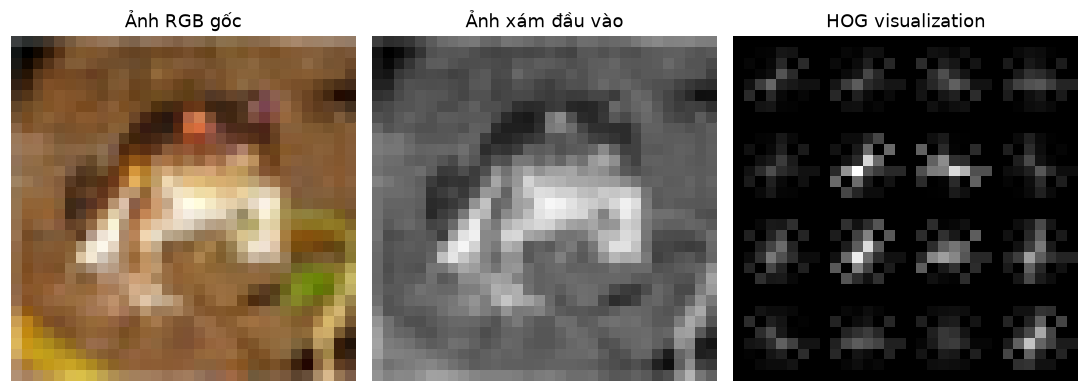

In [4]:
hog_features, hog_image = hog(
    gray_image,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True,
)

print(f"HOG feature vector shape: {hog_features.shape}")
print(f"Số giá trị đặc trưng: {hog_features.size}")
print(
    "Giải thích: gradient được gom theo hướng trong từng cell; các block "
    "chuẩn hóa lân cận giúp mô tả cạnh bớt nhạy với thay đổi độ sáng tổng thể."
)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].imshow(sample_image)
axes[0].set_title("Ảnh RGB gốc")
axes[1].imshow(gray_image, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Ảnh xám đầu vào")
axes[2].imshow(hog_image, cmap="gray")
axes[2].set_title("HOG visualization")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_hog_visualization.png", dpi=180, bbox_inches="tight")
plt.show()


## 05. Kết luận và giới hạn

- Phân ngưỡng tạo mask nhị phân theo cường độ xám; thay đổi ngưỡng làm thay đổi lượng pixel được chọn.
- Tỷ lệ pixel vượt ngưỡng không cho biết mask có khớp đối tượng cần tách hay không. Muốn đánh giá segmentation cần nhãn chuẩn và chỉ số phù hợp.
- HOG biến đổi ảnh thành vector đặc trưng dựa trên phân bố hướng gradient; hình minh họa giúp quan sát cạnh, nhưng chưa chứng minh chất lượng phân loại.
- Thực nghiệm chỉ dùng một ảnh CIFAR-10 và không huấn luyện/đánh giá bộ phân loại; kết quả không đại diện cho toàn bộ dataset.

### Tài liệu tham khảo

1. Vijaya Kumar Suda (2024), *Data Labeling in Machine Learning with Python*, Chapter 4, “Exploring Image Data”, ví dụ segmentation/HOG, trang in 98–101 (số trang thấy trong kết quả tìm kiếm Google Books). [Google Books](https://books.google.com.vn/books?id=2u_xEAAAQBAJ).
2. [scikit-image: Histogram of Oriented Gradients example](https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_hog.html) — tham khảo API và cách trực quan hóa.

Các giải thích và phần mở rộng được diễn đạt lại cho seminar; không thay thế nội dung đầy đủ của sách. Threshold 60/100/140 là phép so sánh mở rộng của nhóm, còn threshold 100 là ví dụ sách.
